# Notebook 8 (v2) — full-brain release: privacy–utility frontier

Implements `SPEC_NB8.md` (v2). Characterises the **whole-brain release** on OASIS with the settled
mechanism — `z = Σ aₘVₘ`, hard **per-eigenmode-max** bar `bₘ = maxᵢ|Dᵢ·Vₘ|`, all modes noised
(`k_noise=r`), sampled by the rejection-free **direct sampler** — and sets a per-statistic operating
scale. Built-in side question: **do we still need patches?**, answered fairly by a whole-brain `single`
configuration folded into the patch axis.

Engine: `release_noise.py` (Tier-3). Frozen `mode_eigen_mech.py`, `privacy_harness.py`,
`inference_eval.py` are untouched — the per-mode-max bar, the direct sampler and the whole-brain
projection attack are assembled additively. **Empirical privacy only — no formal ε.**

Section map: **§0** setup · **§1** attack controls + oracle · **§1b** motivation (direct≡rejection;
per-mode-max vs L2 coverage) · **§2** per-config baseline · **§3** frontier sweep (scale × patch ×
overlap × statistic) · **§3b** k_check → privacy/utility · **§3c** N-subject influence · **§4**
reconstruction + outlier · **§5** inference validity on the imaging release · **§6** frontier +
operating-scale recommendation + patches-vs-single verdict.

## 0 · Setup, frozen check, configuration

In [1]:
# CAP BLAS THREADS BEFORE importing numpy — else BLAS initialises multi-threaded and every tiny
# per-patch SVD spawns ~cpu_count threads (oversubscription); task parallelism then comes from joblib.
import os
for _v in ("OMP_NUM_THREADS","MKL_NUM_THREADS","OPENBLAS_NUM_THREADS","NUMEXPR_NUM_THREADS","VECLIB_MAXIMUM_THREADS"):
    os.environ[_v] = "1"
import sys, hashlib, time, numpy as np, pandas as pd, matplotlib.pyplot as plt
for c in [".", "work", os.path.expanduser("~/harness")]:
    if os.path.exists(os.path.join(c, "privacy_harness.py")): sys.path.insert(0, c); break
import privacy_harness as ph, mode_eigen_mech as me, tiling as T
import full_release_attacks as fra, release_noise as R
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
FROZEN = {"privacy_harness.py": "f03e766b265b4b0b253ce3a8eb94cb53ea76662544ea0b1b9db102f8f29015b4",
          "inference_eval.py":  "0bd08830469858a9332a5cfddc6c332a894dc318b09efda42a9ba8fa6c2b2018",
          "mode_eigen_mech.py": None}
for f, h in FROZEN.items():
    p = next((os.path.join(c, f) for c in [".", "work", os.path.expanduser("~/harness")]
              if os.path.exists(os.path.join(c, f))), None)
    if p and h: print(f"  {f}: {'OK' if hashlib.sha256(open(p,'rb').read()).hexdigest()==h else 'CHANGED!'}")
    elif p:     print(f"  {f}: present (core, not hash-pinned here)")

  privacy_harness.py: OK
  inference_eval.py: OK
  mode_eigen_mech.py: present (core, not hash-pinned here)


In [2]:
USE_OASIS = True                 # False -> portable phantom + reduced grid (end-to-end validation)
BLEND     = "pou_energy"         # fixed for the frontier (average is the parked secondary)
from joblib import Parallel, delayed
SEED = 0
CKPT_DIR = os.path.abspath("nb8_ckpt")      # §3 frontier is cached here; delete to force a recompute

if USE_OASIS:
    N          = 40
    PATCHES    = {"3x3x3": (3,3,3), "5x5x5": (5,5,5), "7x7x7": (7,7,7), "single": "single"}
    OVERLAPS   = [0.0, 0.25, 0.5]           # patched only; `single` has none
    STATS      = ["mean", "median", "variance"]
    TARGETS    = ["worst", "ksigma"]
    SCALES     = [1, 2, 3, 5, 8, 12]        # original config (matches the cached RES); extend here if wanted
    KCHECKS    = [8, 16, 26, None]          # None = r (full-rank policing)
    N_SWEEP    = [20, 40, 60, 80, 100]
    REP_PATCH  = "5x5x5"; REP_SCALE = 5; KC_SCALES = [1, 12]
    N_TRIALS, N_REL, N_MC = 4000, 50, 200
else:
    N          = 30
    PATCHES    = {"5x5x5": (5,5,5), "single": "single"}
    OVERLAPS   = [0.5]
    STATS      = ["mean", "variance"]
    TARGETS    = ["worst"]
    SCALES     = [1, 4, 10, 40, 100]
    KCHECKS    = [8, None]
    N_SWEEP    = [15, 20, 30]
    REP_PATCH  = "5x5x5"; REP_SCALE = 4; KC_SCALES = [1, 10]
    N_TRIALS, N_REL, N_MC = 1500, 20, 80

N_JOBS = 20                   # one single-threaded task per core (BLAS capped above)
PKW    = dict(n_jobs=N_JOBS, verbose=10, inner_max_num_threads=1)   # verbose -> live progress
REP_PATCH_PS = PATCHES[REP_PATCH]
print(f"patches={list(PATCHES)} overlaps={OVERLAPS} stats={STATS} targets={TARGETS}")
print(f"scales={SCALES}")
print(f"N={N} n_trials={N_TRIALS} n_rel={N_REL} n_mc={N_MC} n_jobs={N_JOBS} (cores, 1 BLAS thread each)")

patches=['3x3x3', '5x5x5', '7x7x7', 'single'] overlaps=[0.0, 0.25, 0.5] stats=['mean', 'median', 'variance'] targets=['worst', 'ksigma']
scales=[1, 2, 3, 5, 8, 12]
N=40 n_trials=4000 n_rel=50 n_mc=200 n_jobs=20 (cores, 1 BLAS thread each)


In [3]:
# substrate: OASIS gray-matter maps (whole volume) or a portable phantom
def gm_mask(volumes):
    from scipy import ndimage as ndi
    gm = np.asarray(volumes, float).mean(0); fin = np.isfinite(gm) & (gm > 0)
    try:
        from skimage.filters import threshold_otsu; thr = float(threshold_otsu(gm[fin]))
    except Exception: thr = float(np.percentile(gm[fin], 60))
    m = ndi.binary_fill_holes(gm > thr); lab, n = ndi.label(m)
    if n > 1:
        sz = ndi.sum(np.ones_like(lab), lab, range(1, n+1)); m = lab == (1 + int(np.argmax(sz)))
    return m & np.isfinite(gm)
if USE_OASIS:
    try:
        SUB = T.load_oasis_volumes(n=max(N + 20, 120)); VOLS = np.asarray(SUB["volumes"])
        MASK = gm_mask(VOLS); SUBSTRATE = "OASIS gray-matter maps"
    except Exception as e:
        USE_OASIS = False; print("OASIS unavailable ->", repr(e))
if not USE_OASIS:
    SUB = T.make_phantom(shape=(16,16,14), M=2*N+20, N=N, seed=0)
    VOLS = SUB["volumes"]; MASK = SUB["mask"]; SUBSTRATE = "synthetic phantom"
COHORT = VOLS[:N]
print(f"substrate: {SUBSTRATE} | volumes {VOLS.shape} | in-mask voxels p = {int(MASK.sum())} | r = N-1 = {N-1}")

# targets per statistic (worst-covered under the L2 bar = discriminating; ksigma = synthetic outlier)
TGT = {st: R.select_targets(COHORT, MASK, st) for st in STATS}
for st in STATS:
    print(f"  {st:>8}: worst-subject #{TGT[st]['worst']}  istar #{TGT[st]['istar']}")

[fetch_oasis_vbm] Dataset directory found: /users/lukasschuler/nilearn_data/oasis1
substrate: OASIS gray-matter maps | volumes (120, 91, 109, 91) | in-mask voxels p = 287405 | r = N-1 = 39
      mean: worst-subject #19  istar #37
    median: worst-subject #37  istar #0
  variance: worst-subject #4  istar #37


## 1 · Attack controls + oracle

Sanity that the whole-brain projection attack behaves: a near-noiseless release is near-perfectly
identifiable (advantage → ~1), overwhelming noise washes it out (→ ~0.5, chance). The **oracle** check:
at `k_check=0` the direct sampler is exactly `N(0, scale²·Cov)`, so the projected-score variance must
equal `scale²·(Δᵀ Cov Δ)` analytically (no bar, closed form).

In [4]:
# control + oracle both on the cheap `single` release (substrate-agnostic sanity, 1 SVD)
gi, go, ri, ro, d = R.two_worlds(COHORT, MASK, "mean", "single", 0.5, BLEND, TGT["mean"]["worst"])
rng = np.random.default_rng(SEED)
ctrl = R.advantage_sweep(gi, go, ri, ro, d, [0.02, 1e4], None, N_TRIALS, rng)
# advantage = TPR - FPR: 1 = perfect identification, 0 = chance (NOT 0.5)
print(f"control: near-zero noise adv={ctrl[0]['advantage']:.3f} (expect ~1);  "
      f"huge noise adv={ctrl[1]['advantage']:.3f} (expect ~0 = chance)")

# oracle at k_check=0 on the single whole-brain release above (pure covariance Gaussian)
sg = ri                                   # reuse the control's single in-world release
dvec = (gi - go)
dproj = sg.V.T @ dvec
var_analytic = (1.0**2) * float(np.sum(sg.lam * dproj**2))      # scale=1, Cov = V diag(lam) V^T
emp = sg.project_scores(dvec, 20000, np.random.default_rng(1), scale=1.0, k_check=0)
print(f"oracle k_check=0: var(projected) empirical={emp.var():.4g}  analytic={var_analytic:.4g}  "
      f"ratio={emp.var()/var_analytic:.3f} (expect ~1)")

control: near-zero noise adv=1.000 (expect ~1);  huge noise adv=0.217 (expect ~0 = chance)
oracle k_check=0: var(projected) empirical=0.613  analytic=0.611  ratio=1.003 (expect ~1)


## 1b · Motivation — *why* we changed the mechanism (self-contained)

Two changes from the handed-over version are justified here directly, so the notebook stands alone.

**(A) The direct sampler ≡ the rejection mechanism.** Because the modes are independent, an *accepted*
draw and a *tail-filled* (fallback) draw come from the identical folded-tail-beyond-bar law, so the
released noise — hence privacy and utility — does not depend on the fallback rate. We therefore drop
rejection for a rejection-free inverse-CDF sampler. Shown two ways: (i) the entry-wise output
covariance of the direct sampler lands on the frozen rejection sampler's, on the `y=x` line; (ii) an
output metric (projected-score std) stays flat as the fallback rate is swept from ~99% down via
`max_draws` — i.e. the output is distribution-neutral to fallback.

**(B) Per-eigenmode-max vs L2 coverage.** The handed-over bar `bₘ=|D_{i*}·Vₘ|` polices one subject
`i*`; the per-mode-max bar `bₘ=maxᵢ|Dᵢ·Vₘ|` polices the worst subject *in every mode*, so it covers
every (subject, mode) pair by construction. The per-subject coverage curves make the gap concrete.

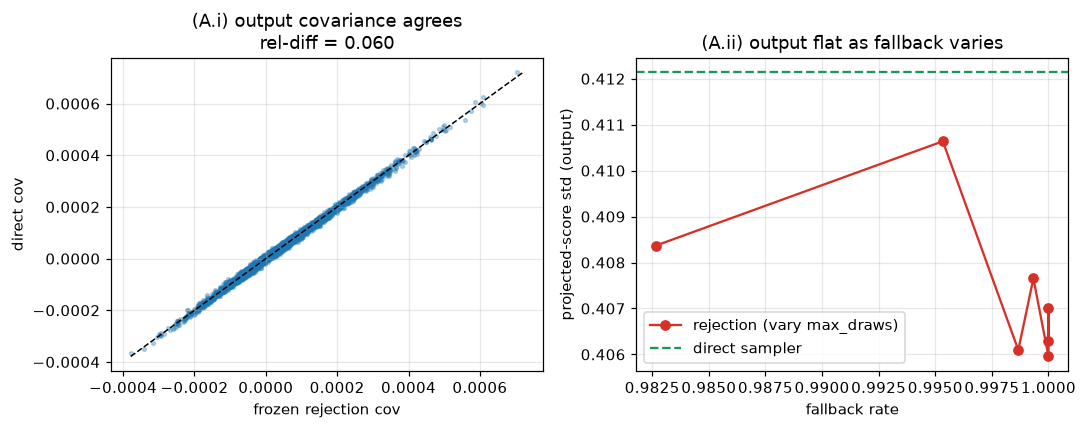

[A] covariance rel-diff 0.060 (<0.08 OK); output std flat across fallback 0.98-1.00 vs direct 0.412


In [ ]:
# (A) equivalence — on a single 5^3 patch so the covariance is 125x125 (reuse frozen L2 bar for apples-to-apples)
src = ph.ArrayBlockSource(VOLS, MASK, block_shape=(5,5,5), N=N, seed=SEED)
pool = src.sample(N, np.random.default_rng(0)).reshape(N,5,5,5)
yv, Dv, Sv = ph.loo_artifacts(pool, ph.pipeline_mean)
r = N - 1
fm = me.mech_mode_eigen(yv, Dv, Sv, scale=3.0, k_check=r, max_draws=600, keep_modes=True)
Zf = np.array([fm.sample(np.random.default_rng(1000+i)) for i in range(4000)])          # frozen rejection
V, lam, bar_l2, _ = R.mode_bundle(Dv.reshape(N,-1), "l2")
Zd = R.draw_coeffs(lam, bar_l2, 3.0, r, 4000, np.random.default_rng(7)) @ V.T            # direct, same L2 bar
cf, cd = np.cov(Zf.T), np.cov(Zd.T)
    SUB = T.make_phantom(shape=(16,16,14), M=2*N+20, N=N, seed=0)
    VOLS = SUB["volumes"]; MASK = SUB["mask"]; SUBSTRATE = "synthetic phantom"
COHORT = VOLS[:N]
print(f"substrate: {SUBSTRATE} | volumes {VOLS.shape} | in-mask voxels p = {int(MASK.sum())} | r = N-1 = {N-1}")

# targets per statistic (worst-covered under the L2 bar = discriminating; ksigma = synthetic outlier)
TGT = {st: R.select_targets(COHORT, MASK, st) fo
iu = np.triu_indices(cf.shape[0])
reldiff = np.linalg.norm(cf - cd) / np.linalg.norm(cf)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(cf[iu], cd[iu], s=6, alpha=.3, color="#1f78b4")
lim = [min(cf[iu].min(), cd[iu].min()), max(cf[iu].max(), cd[iu].max())]
ax[0].plot(lim, lim, "k--", lw=1); ax[0].set_xlabel("frozen rejection cov"); ax[0].set_ylabel("direct cov")
ax[0].set_title(f"(A.i) output covariance agrees\nrel-diff = {reldiff:.3f}")

# (A.ii) projected-score std vs fallback rate, swept via max_draws
dirp = (yv.reshape(-1))                                     # an arbitrary probe direction (the mean map)
dproj = V.T @ dirp
fr, sd_out = [], []
for mdw in [1, 2, 4, 8, 20, 60, 200]:
    fmk = me.mech_mode_eigen(yv, Dv, Sv, scale=3.0, k_check=r, max_draws=mdw, keep_modes=True)
    zk = np.array([fmk.sample(np.random.default_rng(i)) for i in range(1500)])
    fr.append(float(getattr(fmk, "fallback_rate", np.nan))); sd_out.append(float((zk @ dirp).std()))
direct_sd = float((R.draw_coeffs(lam, bar_l2, 3.0, r, 4000, np.random.default_rng(9)) @ V.T @ dirp).std())
ax[1].plot(fr, sd_out, "o-", color="#d73027", label="rejection (vary max_draws)")
ax[1].axhline(direct_sd, color="#1a9850", ls="--", label="direct sampler")
ax[1].set_xlabel("fallback rate"); ax[1].set_ylabel("projected-score std (output)")
ax[1].set_title("(A.ii) output flat as fallback varies"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"[A] covariance rel-diff {reldiff:.3f} (<0.08 OK); output std flat across fallback "
      f"{min(fr):.2f}-{max(fr):.2f} vs direct {direct_sd:.3g}")

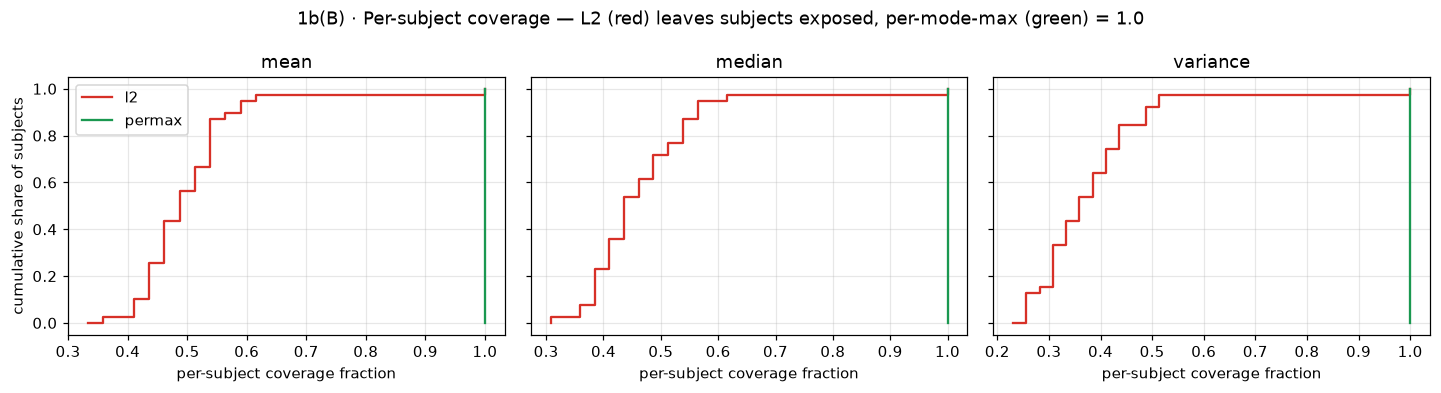

    stat    bar coverage(mean) coverage(min subj)
    mean     l2          0.498              0.333
    mean permax          1.000              1.000
  median     l2          0.464              0.308
  median permax          1.000              1.000
variance     l2          0.378              0.231
variance permax          1.000              1.000


In [6]:
# (B) per-subject coverage, L2 vs per-mode-max, on the whole-brain single release (per statistic)
fig, axes = plt.subplots(1, len(STATS), figsize=(4.4*len(STATS), 3.6), squeeze=False, sharey=True)
covsum = {}
for a, st in zip(axes[0], STATS):
    sg = R.build_release(COHORT, MASK, st, "single")
    proj = sg._proj                                         # (N, r) = D @ V
    istar = int(np.argmax(np.linalg.norm(proj, axis=1)))    # ||proj_i|| = ||D_i|| (V orthonormal)
    for bk, col in zip(["l2", "permax"], ["#d73027", "#1a9850"]):
        bar = np.abs(proj).max(0) if bk == "permax" else np.abs(proj[istar])
        per_subj = (np.abs(proj) <= bar[None, :]).mean(1)   # coverage per subject
        covsum[(st, bk)] = (float(per_subj.mean()), float(per_subj.min()))
        a.plot(np.sort(per_subj), np.linspace(0, 1, N), drawstyle="steps-post", color=col, label=bk)
    a.set_title(st); a.set_xlabel("per-subject coverage fraction")
    if a is axes[0][0]: a.set_ylabel("cumulative share of subjects"); a.legend()
fig.suptitle("1b(B) · Per-subject coverage — L2 (red) leaves subjects exposed, per-mode-max (green) = 1.0")
plt.tight_layout(); plt.show()
print(pd.DataFrame([(st, bk, f"{m:.3f}", f"{mn:.3f}") for (st, bk), (m, mn) in covsum.items()],
                   columns=["stat","bar","coverage(mean)","coverage(min subj)"]).to_string(index=False))

## 2 · Per-config baseline (at the operating scale)

One row per (patch, overlap, statistic): membership advantage (worst-covered target), coverage,
patch count, and the utility panel — a sanity pass before the full sweep.

In [7]:
REP_SCALE_B = REP_SCALE
def _baseline(nm, ps, ov):
    st = "mean"
    tgt = TGT[st]["worst"]
    gi, go, ri, ro, dv = R.two_worlds(COHORT, MASK, st, ps, (ov or 0.5), BLEND, tgt)
    adv = R.advantage_sweep(gi, go, ri, ro, dv, [REP_SCALE_B], None, N_TRIALS,
                            np.random.default_rng(1))[0]
    u = R.release_utility(ri, REP_SCALE_B, None, np.random.default_rng(2), n_rel=N_REL)
    return dict(patch=nm, overlap=("-" if ov is None else ov), n_patches=ri.n_patches,
                coverage=round(ri.coverage()["overall"], 3), advantage=round(adv["advantage"], 3),
                rel_mse=round(u["rel_mse"], 4), spearman=round(u["spearman"], 3),
                ssim=round(u["ssim"], 3))
cfgs = [(nm, ps, (None if ps=="single" else ov))
        for nm, ps in PATCHES.items() for ov in (OVERLAPS if ps!="single" else [None])]
BASE = pd.DataFrame(Parallel(**PKW)(delayed(_baseline)(nm, ps, ov) for nm, ps, ov in cfgs))
print(f"baseline @ scale={REP_SCALE_B}, statistic=mean, target=worst-covered:")
print(BASE.to_string(index=False))

[Parallel(n_jobs=20)]: Using backend LokyBackend with 20 concurrent workers.
/indirect/student/lukasschuler/test/wp15/infrastructure/privacy_dev/tiling.py:362: UserWarning: SSIM disabled (ModuleNotFoundError: No module named 'skimage'); other metrics unaffected.
  warnings.warn(f"SSIM disabled ({type(e).__name__}: {e}); other metrics unaffected.")
/indirect/student/lukasschuler/test/wp15/infrastructure/privacy_dev/tiling.py:362: UserWarning: SSIM disabled (ModuleNotFoundError: No module named 'skimage'); other metrics unaffected.
  warnings.warn(f"SSIM disabled ({type(e).__name__}: {e}); other metrics unaffected.")
/indirect/student/lukasschuler/test/wp15/infrastructure/privacy_dev/tiling.py:362: UserWarning: SSIM disabled (ModuleNotFoundError: No module named 'skimage'); other metrics unaffected.
  warnings.warn(f"SSIM disabled ({type(e).__name__}: {e}); other metrics unaffected.")
/indirect/student/lukasschuler/test/wp15/infrastructure/privacy_dev/tiling.py:362: UserWarning: SSIM dis

baseline @ scale=5, statistic=mean, target=worst-covered:
 patch overlap  n_patches  coverage  advantage  rel_mse  spearman  ssim
 3x3x3     0.0      35995       1.0      1.000   0.0035     0.996 0.994
 3x3x3    0.25      35995       1.0      1.000   0.0035     0.996 0.994
 3x3x3     0.5      35995       1.0      1.000   0.0035     0.996 0.994
 5x5x5     0.0      35761       1.0      1.000   0.0035     0.996 0.994
 5x5x5    0.25       5066       1.0      0.999   0.0035     0.996   NaN
 5x5x5     0.5      35761       1.0      1.000   0.0035     0.996 0.994
 7x7x7     0.0       4518       1.0      1.000   0.0035     0.996   NaN
 7x7x7    0.25       2596       1.0      0.999   0.0035     0.996   NaN
 7x7x7     0.5       4518       1.0      1.000   0.0035     0.996   NaN
single       -          1       1.0      0.511   0.0037     0.997   NaN


[Parallel(n_jobs=20)]: Done  10 out of  10 | elapsed:  4.5min finished


## 3 · Frontier sweep — scale × patch{incl. single} × overlap × statistic (k_check = r)

The core experiment. Every config is swept over the **same scales**, attacked by the **same
whole-brain projection** game and scored on the **same utility panel**. Modes/bar are built once per
(patch, overlap, statistic) and scale is applied at sample time. `single` is the whole brain as one
mode-eigen field — where it lands vs the best patched config is the **patches-vs-single verdict (§6)**.

In [8]:
t0 = time.time()
CFGS = [(nm, ps, (None if ps=="single" else ov))
        for nm, ps in PATCHES.items() for ov in (OVERLAPS if ps!="single" else [None])]
os.makedirs(CKPT_DIR, exist_ok=True); _ckpt = os.path.join(CKPT_DIR, "RES.csv")

if os.path.exists(_ckpt):
    RES = pd.read_csv(_ckpt)
    print(f"LOADED cached frontier: {_ckpt} ({len(RES)} rows, scales={sorted(RES.scale.unique())}) "
          f"-- skipping the sweep. Delete the nb8_ckpt/ folder to force a recompute.")
else:
    print(f"{len(CFGS)} configs x {len(STATS)} stats = {len(CFGS)*len(STATS)} parallel jobs "
          f"(each builds 1 full-cohort release [= utility + real-target in-world] + extra attack worlds)")
    def _config_job(nm, ps, ov, st):
        ovv = 0.5 if ov is None else ov
        rng = np.random.default_rng(hash((nm, ov, st)) % 2**31)
        rel_full = R.build_release(COHORT, MASK, st, ps, ovv, BLEND)      # shared below
        cov = rel_full.coverage()["overall"]; npat = rel_full.n_patches
        ovs = "-" if ov is None else ov
        urows = []
        for sc in SCALES:
            u = R.release_utility(rel_full, sc, None, rng, n_rel=N_REL)
            urows.append(dict(patch=nm, overlap=ovs, stat=st, scale=sc, rel_mse=u["rel_mse"],
                              spearman=u["spearman"], ssim=u["ssim"], nc_gap=u["neighbour_corr_gap"]))
        arows = []
        for target in TARGETS:
            tgt = TGT[st][target]
            gi, go, ri, ro, dv = R.two_worlds(COHORT, MASK, st, ps, ovv, BLEND, tgt,
                                              rel_full=(None if target == "ksigma" else rel_full))
            for rw in R.advantage_sweep(gi, go, ri, ro, dv, SCALES, None, N_TRIALS, rng):
                arows.append(dict(patch=nm, overlap=ovs, stat=st, target=target, scale=rw["scale"],
                                  advantage=rw["advantage"], adv_lo=rw["adv_ci"][0],
                                  adv_hi=rw["adv_ci"][1], coverage=cov, n_patches=npat))
        return arows, urows
    jobs = [(nm, ps, ov, st) for (nm, ps, ov) in CFGS for st in STATS]
    out = Parallel(**PKW)(delayed(_config_job)(nm, ps, ov, st) for nm, ps, ov, st in jobs)
    ADV = pd.DataFrame([r for a, _ in out for r in a])
    UTL = pd.DataFrame([r for _, u in out for r in u])
    RES = ADV.merge(UTL, on=["patch","overlap","stat","scale"], how="left")
    RES.to_csv(_ckpt, index=False)
    print(f"sweep done in {time.time()-t0:.0f}s | rows: {len(RES)} | cached -> {_ckpt}")
RES["overlap"] = RES["overlap"].astype(str)     # uniform after CSV round-trip ("-", "0.0", "0.25", "0.5")

LOADED cached frontier: /indirect/student/lukasschuler/test/wp15/infrastructure/privacy_dev/nb8_ckpt/RES.csv (360 rows, scales=[np.int64(1), np.int64(2), np.int64(3), np.int64(5), np.int64(8), np.int64(12)]) -- skipping the sweep. Delete the nb8_ckpt/ folder to force a recompute.


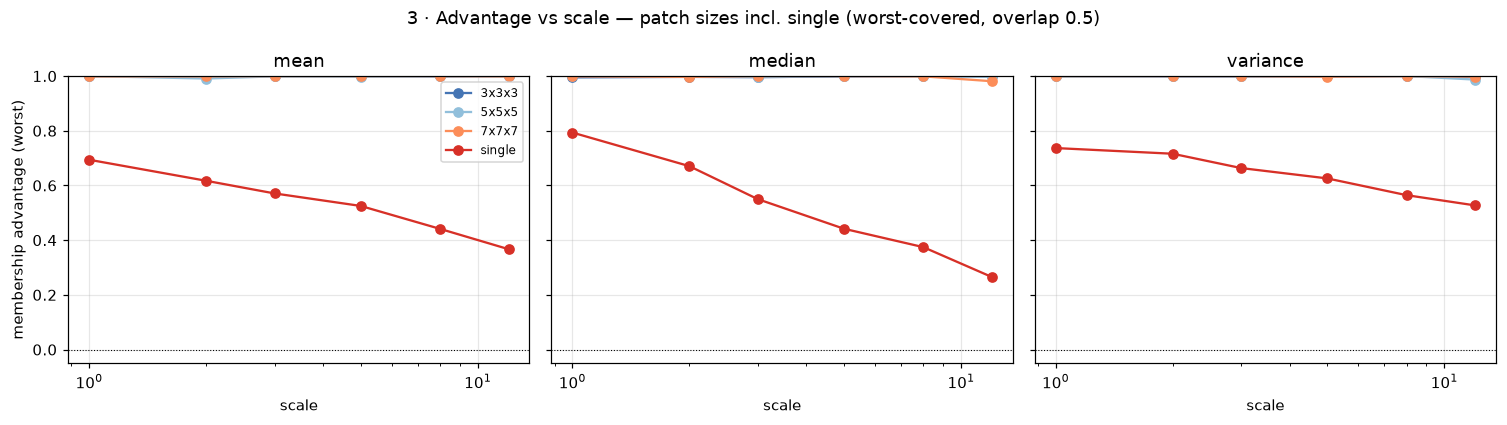

overlap effect (patch=5x5x5, mean, worst) — advantage by scale x overlap:
overlap    0.0   0.25    0.5
scale                       
1        1.000  1.000  1.000
2        0.999  0.999  0.991
3        1.000  0.995  0.999
5        0.999  0.999  0.998
8        0.999  0.999  1.000
12       0.999  0.999  1.000


In [9]:
# advantage vs scale, per statistic, one line per patch (worst-covered target, overlap=0.5 for patched)
def _ov_pick(df): return df[df.overlap.astype(str).isin(["-", "0.5"])]   # single + overlap-0.5 patched
fig, axes = plt.subplots(1, len(STATS), figsize=(4.6*len(STATS), 3.9), squeeze=False, sharey=True)
cols = {"3x3x3":"#4575b4","5x5x5":"#91bfdb","7x7x7":"#fc8d59","single":"#d73027"}
for a, st in zip(axes[0], STATS):
    sub = _ov_pick(RES[(RES.stat==st) & (RES.target=="worst")])
    for nm in PATCHES:
        s = sub[sub.patch==nm].sort_values("scale")
        if len(s): a.plot(s.scale, s.advantage, "o-", color=cols.get(nm), label=nm)
    a.set_title(st); a.set_xlabel("scale"); a.set_xscale("log"); a.set_ylim(-0.05, 1.0)
    a.axhline(0.0, color="k", lw=.7, ls=":")   # advantage = TPR-FPR; 0 = chance
    if a is axes[0][0]: a.set_ylabel("membership advantage (worst)"); a.legend(fontsize=8)
fig.suptitle("3 · Advantage vs scale — patch sizes incl. single (worst-covered, overlap 0.5)")
plt.tight_layout(); plt.show()

# overlap-compounding read (patched only, 5x5x5, mean)
sub = RES[(RES.patch==REP_PATCH) & (RES.stat=="mean") & (RES.target=="worst")]
piv = sub.pivot_table(index="scale", columns="overlap", values="advantage")
print(f"overlap effect (patch={REP_PATCH}, mean, worst) — advantage by scale x overlap:")
print(piv.round(3).to_string())

## 3b · k_check → privacy / utility

At `5³`, one low and one high scale, sweep the policing depth `k_check` per statistic and target.
Hypothesis: advantage **rises** as `k_check` falls (tail modes left with only natural noise → leak),
at **lower** distortion — the direct test of whether full-rank policing (`k_check = r`) earns its cost.
Inference effect (mean release) is read alongside for a couple of depths.

[Parallel(n_jobs=20)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done   2 out of   6 | elapsed: 20.3min remaining: 40.6min
[Parallel(n_jobs=20)]: Done   3 out of   6 | elapsed: 20.5min remaining: 20.5min
[Parallel(n_jobs=20)]: Done   4 out of   6 | elapsed: 21.0min remaining: 10.5min
[Parallel(n_jobs=20)]: Done   6 out of   6 | elapsed: 23.4min finished


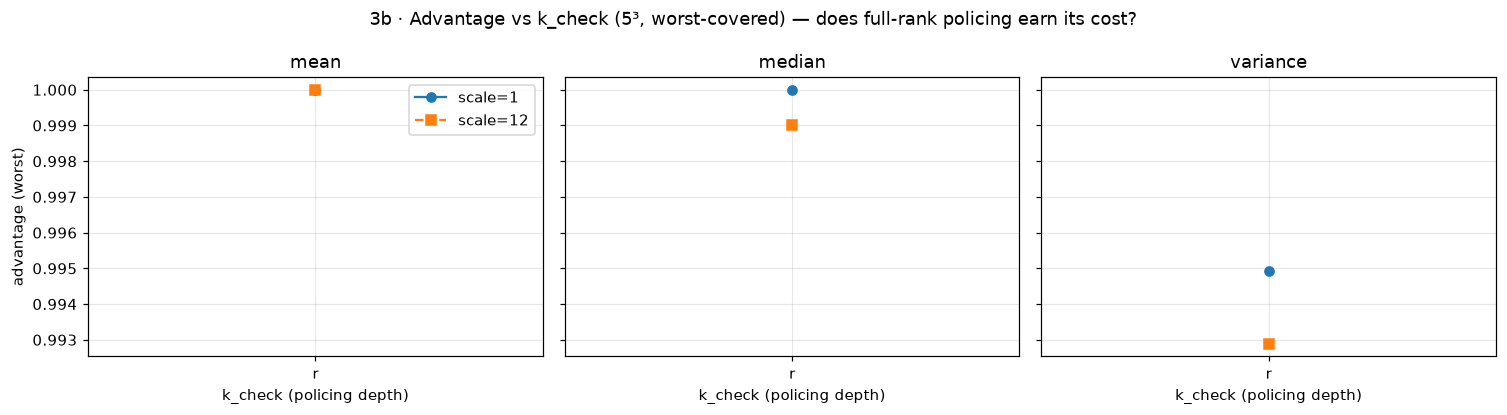

k_check             8     16     26      r
stat     scale                            
mean     1      0.999  1.000  1.000  1.000
         12     0.998  1.000  0.999  1.000
median   1      0.999  0.998  0.999  1.000
         12     0.996  0.994  1.000  0.999
variance 1      0.998  1.000  1.000  0.995
         12     1.000  0.994  1.000  0.993


In [10]:
kc_labels = [("r" if k is None else str(k)) for k in KCHECKS]
def _kc_job(st, target):                     # one two-world build per (stat,target), reused across scales
    tgt = TGT[st][target]
    gi, go, ri, ro, dv = R.two_worlds(COHORT, MASK, st, PATCHES[REP_PATCH], 0.5, BLEND, tgt)
    out = []
    for sc in KC_SCALES:
        for rw in R.kcheck_sweep(gi, go, ri, ro, dv, sc, KCHECKS, N_TRIALS, np.random.default_rng(3)):
            out.append(dict(stat=st, target=target, scale=sc,
                            k_check=("r" if rw["k_check"] is None else rw["k_check"]),
                            advantage=rw["advantage"]))
    return out
_kcjobs = [(st, tg) for st in STATS for tg in TARGETS]
KC = pd.DataFrame([r for rows in Parallel(**PKW)(delayed(_kc_job)(st, tg) for st, tg in _kcjobs) for r in rows])
fig, axes = plt.subplots(1, len(STATS), figsize=(4.6*len(STATS), 3.8), squeeze=False, sharey=True)
for a, st in zip(axes[0], STATS):
    for sc, ls in zip(KC_SCALES, ["o-", "s--"]):
        s = KC[(KC.stat==st) & (KC.target=="worst") & (KC.scale==sc)]
        s = s.set_index("k_check").loc[[l for l in kc_labels if l in set(s.k_check)]]
        a.plot(range(len(s)), s.advantage, ls, label=f"scale={sc}")
        a.set_xticks(range(len(s))); a.set_xticklabels(s.index)
    a.set_title(st); a.set_xlabel("k_check (policing depth)")
    if a is axes[0][0]: a.set_ylabel("advantage (worst)"); a.legend()
fig.suptitle("3b · Advantage vs k_check (5³, worst-covered) — does full-rank policing earn its cost?")
plt.tight_layout(); plt.show()
print(KC[KC.target=="worst"].pivot_table(index=["stat","scale"], columns="k_check",
      values="advantage").round(3).to_string())

## 3c · N-subject influence

Vary the cohort size `N` at `5³` and a representative scale. Prediction (bar study §1.8): more subjects
does **not** buy privacy the usual way — the bar scales with each subject's influence, so dilution
cancels; N acts only through rank/aggregation, which plateaus. Expect advantage roughly flat / mildly
changing with N, not a clean drop.

[Parallel(n_jobs=20)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done   3 out of  30 | elapsed:  2.3min remaining: 21.1min
[Parallel(n_jobs=20)]: Done   7 out of  30 | elapsed:  4.4min remaining: 14.4min
[Parallel(n_jobs=20)]: Done  11 out of  30 | elapsed:  7.2min remaining: 12.4min
[Parallel(n_jobs=20)]: Done  15 out of  30 | elapsed:  8.5min remaining:  8.5min
[Parallel(n_jobs=20)]: Done  19 out of  30 | elapsed: 13.9min remaining:  8.0min
[Parallel(n_jobs=20)]: Done  23 out of  30 | elapsed: 16.5min remaining:  5.0min
[Parallel(n_jobs=20)]: Done  27 out of  30 | elapsed: 23.1min remaining:  2.6min
[Parallel(n_jobs=20)]: Done  30 out of  30 | elapsed: 35.1min finished


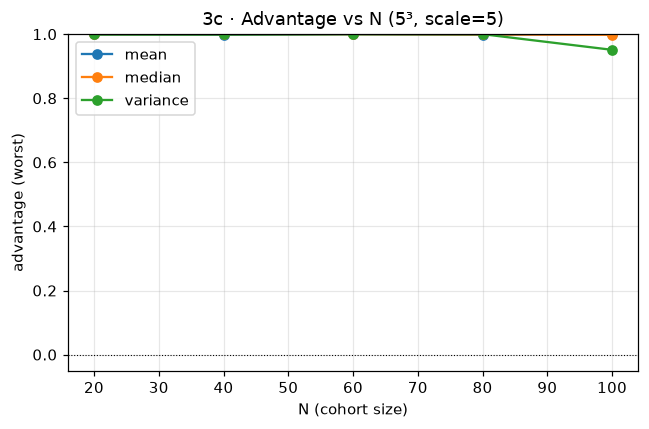

stat   mean  median  variance
N                            
20    0.999   1.000     0.999
40    0.998   1.000     0.999
60    1.000   1.000     1.000
80    0.998   0.999     1.000
100   0.999   0.998     0.951


In [11]:
def _n_job(n, st, target):
    coh = VOLS[:n]; tgt = R.select_targets(coh, MASK, st)[target]
    gi, go, ri, ro, dv = R.two_worlds(coh, MASK, st, PATCHES[REP_PATCH], 0.5, BLEND, tgt)
    adv = R.advantage_sweep(gi, go, ri, ro, dv, [REP_SCALE], None, N_TRIALS,
                            np.random.default_rng(4))[0]["advantage"]
    return dict(N=n, stat=st, target=target, advantage=adv)
_njobs = [(n, st, tg) for n in N_SWEEP for st in STATS for tg in TARGETS]
NS = pd.DataFrame(Parallel(**PKW)(delayed(_n_job)(n, st, tg) for n, st, tg in _njobs))
fig, ax = plt.subplots(figsize=(6, 4))
for st in STATS:
    s = NS[(NS.stat==st) & (NS.target=="worst")].sort_values("N")
    ax.plot(s.N, s.advantage, "o-", label=st)
ax.set_xlabel("N (cohort size)"); ax.set_ylabel("advantage (worst)"); ax.set_ylim(-0.05, 1.0)
ax.axhline(0.0, color="k", lw=.7, ls=":"); ax.set_title(f"3c · Advantage vs N (5³, scale={REP_SCALE})")
ax.legend(); plt.tight_layout(); plt.show()
print(NS[NS.target=="worst"].pivot_table(index="N", columns="stat", values="advantage").round(3).to_string())

## 4 · Reconstruction + outlier-detectability (mean release)

For the identifiable **mean** release the attacker inverts the group mean to recover a target:
`x̂ = N·R − Σ background = target + N·z`. Two readouts on the `ksigma` target (a genuine outlier, so
the clean flag is True): (i) does the privatized reconstruction still trip the supervisor-style
outlier flag, and (ii) the reconstruction error `‖x̂ − target‖ / ‖target‖`. Note the `×N`
amplification: the released per-subject-sized noise is multiplied by N in the inversion, so the
reconstruction is swamped by noise — the flag is a coarse diagnostic and the membership advantage
(§3) is the sharper privacy measure.

In [12]:
mb = MASK.reshape(-1)
relS = R.build_release(COHORT, MASK, "mean", "single")
# ksigma synthetic target placed in the cohort (drop subject 0, insert ksigma)
ksig = TGT["mean"]["ksigma"].reshape(-1)[mb]
bg = COHORT.reshape(N,-1)[1:, mb]                       # N-1 background
rows = []
for sc in [SCALES[0], REP_SCALE, SCALES[-1]]:
    nm = R.fixed_noise(relS, sc, None)
    od = fra.outlier_detectability(bg, ksig, N, nm, np.random.default_rng(5), n_rel=min(200, 5*N_REL))
    # reconstruction error over releases
    errs = []
    for _ in range(min(200, 5*N_REL)):
        z = nm.sample(np.random.default_rng(np.random.randint(1<<30)))
        x_hat = ksig + N * z
        errs.append(np.linalg.norm(x_hat - ksig) / (np.linalg.norm(ksig) + 1e-12))
    rows.append(dict(scale=sc, clean_z_flag=od["clean_z_flag"], private_z_rate=round(od["private_z_rate"],3),
                     private_iqr_rate=round(od["private_iqr_rate"],3),
                     recon_err=round(float(np.mean(errs)), 3)))
    print(f"  scale {sc} done")
print("mean release, ksigma target (clean_z_flag should be True = a genuine outlier):")
print(pd.DataFrame(rows).to_string(index=False))

  scale 1 done
  scale 5 done
  scale 12 done
mean release, ksigma target (clean_z_flag should be True = a genuine outlier):
 scale  clean_z_flag  private_z_rate  private_iqr_rate  recon_err
     1          True             1.0               1.0      0.721
     5          True             1.0               1.0      1.453
    12          True             1.0               1.0      2.945


## 5 · Inference validity on the imaging release (mass-univariate, corrected)

The refinement that closes the option-B caveat: run a per-voxel one-sample t-test **on the released
imaging map**, not a tabular proxy. Null = sign-flip permutation of the centered cohort deviations
(true per-voxel mean 0, variance preserved) → clean corrected FWER ≈ α; the mechanism noise is added
to the released mean map and the test re-run → private FWER = Type-1 inflation. A fixed regional effect
gives power. Bonferroni (FWER) and Benjamini–Hochberg (FDR). The mechanism's non-Gaussian hard-bar
noise is expected to inflate Type-1 as scale rises; this quantifies by how much, per config.

[Parallel(n_jobs=20)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done   2 out of   8 | elapsed:  1.2min remaining:  3.5min
[Parallel(n_jobs=20)]: Done   3 out of   8 | elapsed:  1.2min remaining:  2.0min
[Parallel(n_jobs=20)]: Done   4 out of   8 | elapsed:  1.2min remaining:  1.2min
[Parallel(n_jobs=20)]: Done   5 out of   8 | elapsed: 13.3min remaining:  8.0min
[Parallel(n_jobs=20)]: Done   6 out of   8 | elapsed: 13.5min remaining:  4.5min
[Parallel(n_jobs=20)]: Done   8 out of   8 | elapsed: 13.7min finished


clean FWER should sit near alpha=0.05; private FWER is the Type-1 inflation from the noise:
config  scale  FWER_clean  FWER_priv  BHfp_clean  BHfp_priv  pow_clean  pow_priv
 5x5x5    0.0       0.040      0.040       0.045      0.045      0.980     0.980
 5x5x5    1.0       0.040      0.180       0.045      0.200      0.980     0.962
 5x5x5    5.0       0.040      0.995       0.045      1.000      0.980     0.923
 5x5x5   12.0       0.040      1.000       0.045      1.000      0.980     0.861
single    0.0       0.055      0.055       0.055      0.055      0.982     0.982
single    1.0       0.055      0.145       0.055      0.170      0.982     0.963
single    5.0       0.055      0.670       0.055      0.750      0.982     0.927
single   12.0       0.055      0.995       0.055      1.000      0.982     0.865


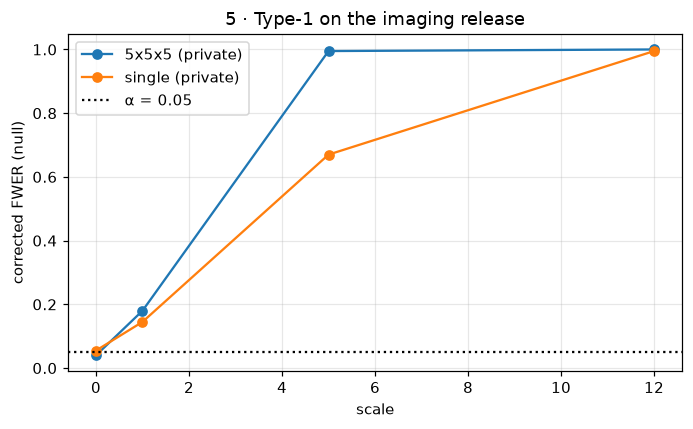

In [13]:
inf_cfgs = [("single", "single", None)] + ([("5x5x5", (5,5,5), 0.5)] if "5x5x5" in PATCHES else [])
inf_scales = sorted({0.0, SCALES[0], REP_SCALE, SCALES[-1]})
def _inf_job(nm, ps, ov, sc):
    relm = R.build_release(COHORT, MASK, "mean", ps, (0.5 if ov is None else ov), BLEND)
    o = R.imaging_inference(relm, COHORT, MASK, sc, None, alpha=0.05, n_mc=N_MC,
                            effect=0.8, region_frac=0.05, seed=SEED)
    return dict(config=nm, scale=sc,
                FWER_clean=round(o["fwer_clean"],3), FWER_priv=round(o["fwer_priv"],3),
                BHfp_clean=round(o["fdr_fp_clean"],3), BHfp_priv=round(o["fdr_fp_priv"],3),
                pow_clean=round(o["pow_bh_clean"],3), pow_priv=round(o["pow_bh_priv"],3))
_ijobs = [(nm, ps, ov, sc) for (nm, ps, ov) in inf_cfgs for sc in inf_scales]
INF = pd.DataFrame(Parallel(**PKW)(delayed(_inf_job)(*j) for j in _ijobs)).sort_values(["config","scale"])
print("clean FWER should sit near alpha=0.05; private FWER is the Type-1 inflation from the noise:")
print(INF.to_string(index=False))
fig, ax = plt.subplots(figsize=(6.4, 4))
for nm in INF.config.unique():
    s = INF[INF.config==nm].sort_values("scale")
    ax.plot(s.scale, s.FWER_priv, "o-", label=f"{nm} (private)")
ax.axhline(0.05, color="k", ls=":", label="α = 0.05")
ax.set_xlabel("scale"); ax.set_ylabel("corrected FWER (null)"); ax.set_title("5 · Type-1 on the imaging release")
ax.legend(); plt.tight_layout(); plt.show()

## 6 · Frontier, operating scale, and the patches-vs-single verdict

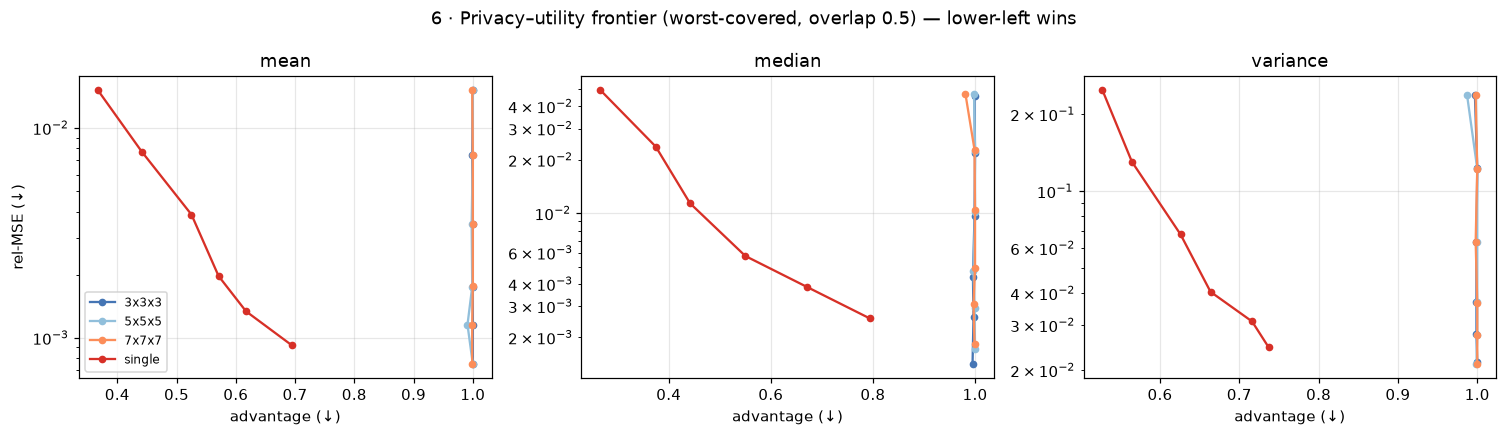

operating scale per statistic (smallest scale with worst-target advantage <= 0.3):
      mean: not reached within tested scales (max scale 12)
    median: scale>=  12  via single  overlap -  (adv 0.265, rel-MSE 0.0496)
  variance: not reached within tested scales (max scale 12)

patches-vs-single (mean, worst): single advantage vs best patched advantage, per scale:
  scale=   1: single 0.694  best-patched 0.996  -> single wins/ties
  scale=   2: single 0.617  best-patched 0.991  -> single wins/ties
  scale=   3: single 0.571  best-patched 0.995  -> single wins/ties
  scale=   5: single 0.525  best-patched 0.998  -> single wins/ties
  scale=   8: single 0.441  best-patched 0.999  -> single wins/ties
  scale=  12: single 0.367  best-patched 0.995  -> single wins/ties


In [14]:
# privacy-utility frontier: advantage vs rel-MSE, per statistic, patch sizes incl. single (overlap 0.5)
fig, axes = plt.subplots(1, len(STATS), figsize=(4.6*len(STATS), 4.0), squeeze=False)
cols = {"3x3x3":"#4575b4","5x5x5":"#91bfdb","7x7x7":"#fc8d59","single":"#d73027"}
for a, st in zip(axes[0], STATS):
    sub = _ov_pick(RES[(RES.stat==st) & (RES.target=="worst")])
    for nm in PATCHES:
        s = sub[sub.patch==nm].sort_values("scale")
        if len(s):
            a.plot(s.advantage, s.rel_mse, "o-", color=cols.get(nm), label=nm, ms=4)
    a.set_title(st); a.set_xlabel("advantage (↓)"); a.set_yscale("log")
    if a is axes[0][0]: a.set_ylabel("rel-MSE (↓)"); a.legend(fontsize=8)
fig.suptitle("6 · Privacy–utility frontier (worst-covered, overlap 0.5) — lower-left wins")
plt.tight_layout(); plt.show()

# operating scale per statistic: smallest scale reaching advantage <= target, best patch
# advantage = TPR-FPR (0 = chance). TARGET_ADV is the "acceptably low" bar — a supervisor judgment call; tune it.
TARGET_ADV = 0.3
print(f"operating scale per statistic (smallest scale with worst-target advantage <= {TARGET_ADV}):")
for st in STATS:
    sub = _ov_pick(RES[(RES.stat==st) & (RES.target=="worst")])
    best = sub[sub.advantage <= TARGET_ADV].sort_values(["scale","rel_mse"])
    if len(best):
        b = best.iloc[0]
        print(f"  {st:>8}: scale>={b.scale:>4}  via {b.patch:<7} overlap {b.overlap}  "
              f"(adv {b.advantage:.3f}, rel-MSE {b.rel_mse:.4f})")
    else:
        print(f"  {st:>8}: not reached within tested scales (max scale {max(SCALES)})")

# patches-vs-single: at each scale, is single at or below the best patched advantage? (mean, worst)
print("\npatches-vs-single (mean, worst): single advantage vs best patched advantage, per scale:")
mm = RES[(RES.stat=="mean") & (RES.target=="worst")]
for sc in SCALES:
    sg = mm[(mm.patch=="single") & (mm.scale==sc)]
    pt = mm[(mm.patch!="single") & (mm.scale==sc)]
    if len(sg) and len(pt):
        sgv = sg.advantage.iloc[0]; best = pt.advantage.min()
        verdict = "single wins/ties" if sgv <= best + 0.02 else "patched wins"
        print(f"  scale={sc:>4}: single {sgv:.3f}  best-patched {best:.3f}  -> {verdict}")

### Read-off (fill from the run)

- **Operating scale**: pick per statistic from the frontier above (mean cheapest, variance most
  expensive, as the bar study predicted). The printed table gives the smallest scale reaching the
  advantage target at the best patch/overlap.
- **Patches vs single**: if `single` sits at or below the best patched advantage at equal utility
  across scales, the tiling/blending machinery is **not** needed for the whole-brain release and the
  pipeline simplifies to one economy-SVD mode-eigen field. If patched dominates at some scales, that is
  the case for keeping patches. (On the phantom, `single` was competitive-to-better — confirm on OASIS.)
- **k_check** (§3b): if advantage rises as `k_check` falls, full-rank policing (`k_check=r`) is
  justified; the utility/inference cost of full policing is the price.
- **N-subjects** (§3c): advantage roughly flat with N confirms that adding subjects does not buy
  privacy — scale is the lever.
- **Inference** (§5): clean FWER ≈ α validates the test; private FWER is the Type-1 inflation the
  hard-bar noise causes — report it as the inference cost at the chosen operating scale.
- **Residual leak**: even at the operating scale the worst subject retains a non-trivial advantage with
  real distortion — the structural aggregation leak, whose fix (composition-aware / formal-DP
  calibration) is out of scope here.